# 28 - Dataset da Camada 2 (recente, 10 m) para o Modelo B

| | |
|---|---|
| **Tarefa do plano** | S2-11 - `train_recente.parquet` |
| **O que faz** | Monta a tabela de treino do modelo de deteção de água atual |
| **Usa** | Sentinel-1, Sentinel-2, Dynamic World, referência seca do radar (20), stack estático (21), JRC mensal |
| **Produz** | `data/processed/training/train_recente.parquet` + dicionário + metadados |

**Ideia simples.** Cada linha é **um píxel de 10 m num mês**, com o que o radar
(Sentinel-1) e o ótico (Sentinel-2) viram, e a resposta: era água?

- O rótulo vem do JRC mensal (30 m). Para cada célula de 30 m sorteada usa-se o
  píxel de 10 m do **centro**, o menos afetado pelas margens da célula.
- O JRC é calculado com o Landsat, um satélite diferente dos dois Sentinel. O
  rótulo é por isso independente das features, o que não acontece no Modelo A.
- Linhas sem valor de Sentinel-1 são retiradas: o Modelo B é um modelo de radar,
  que tem de funcionar com nuvens. As colunas do Sentinel-2 podem estar vazias
  (nuvens, ou meses antes de 2017).
- Os meses vão de 2015 a 2021: quando existem ao mesmo tempo Sentinel-1 e JRC.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, drivers, features, rasters, series, training
from ete import grid as G

cfg = config.load_config()
P = cfg["processing"]
REPORTS = config.path(cfg, "reports", "semana_2")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Construir a tabela

In [2]:
table = training.build_recent(cfg)          # lê os rasters de 10 m mês a mês: demora vários minutos
out = config.path(cfg, "training", "train_recente.parquet")
print("escrito:", out.relative_to(ROOT))
table.head(3).T

camada 2:   0%|          | 0/81 [00:00<?, ?it/s]

escrito: data/processed/training/train_recente.parquet


,0,1,2
month,2015-04,2015-04,2015-04
year,2015,2015,2015
month_num,4,4,4
season,wet,wet,wet
row,1728,1307,640
...,...,...,...
sm_root_cal_district,0.123,0.123,0.123
rain_basin_mm_lag1,90.695,90.695,90.695
rain_district_mm_lag1,77.772,77.772,77.772
sm_cal_basin_lag1,0.113,0.113,0.113


## 2. Controlo de qualidade da tabela

In [3]:
print(f"{len(table):,} linhas x {table.shape[1]} colunas | {table['month'].nunique()} meses | ficheiro {out.stat().st_size / 1e6:.0f} MB")
display(table.groupby(["split", "stratum"], observed=True).size().unstack(fill_value=0))
resumo = table.groupby("split", observed=True).apply(lambda g: pd.Series({
    "linhas": len(g), "água_pct": 100 * g["label_water"].mean(), "cheia_pct": 100 * g["label_flood"].mean(),
    "cheia_pct_real": 100 * np.average(g["label_flood"], weights=g["weight"])}), include_groups=False)
resumo

311,413 linhas x 96 colunas | 73 meses | ficheiro 30 MB


stratum,dry_low,dry_other,ems,flood,permanent
split,,,,,
test,0,0,40000,0,0
train,74416,34450,0,68054,14594
val,31500,14700,0,27999,5700


,linhas,água_pct,cheia_pct,cheia_pct_real
split,,,,
test,"40,000.000",50.000,49.998,59.642
train,"191,514.000",43.155,35.535,0.272
val,"79,899.000",42.177,35.043,0.764


`cheia_pct` é a proporção na amostra (as cheias foram sorteadas de propósito em
maior número). `cheia_pct_real` usa os pesos e dá a proporção verdadeira no
terreno: mostra quão raro é o que o modelo tem de aprender.

## 3. Dicionário de dados e valores em falta

In [4]:
dicionario = training.data_dictionary(table)
dicionario.to_csv(out.with_name(out.stem + "_dicionario.csv"), index=False)
display(dicionario.groupby("grupo").agg(colunas=("coluna", "count"), em_falta_pct_medio=("em_falta_pct", "mean")).round(1))
dicionario[dicionario["em_falta_pct"] > 0].sort_values("em_falta_pct", ascending=False).head(15)

,colunas,em_falta_pct_medio
grupo,,
amostragem,2,0.000
caudal,5,0.000
chuva,14,0.000
dynamic_world,2,12.300
hidrometeorologia,6,0.000
humidade_solo,13,0.000
metadados,9,0.000
rotulo,3,0.000
rotulo_auxiliar,1,0.000


,coluna,grupo,descricao,unidade,tipo,em_falta_pct
45,s2_green,sentinel2,"Sentinel-2: refletância, índices e nº de obser...",,float32,24.600
44,s2_blue,sentinel2,"Sentinel-2: refletância, índices e nº de obser...",,float32,24.600
47,s2_red_edge1,sentinel2,"Sentinel-2: refletância, índices e nº de obser...",,float32,24.600
46,s2_red,sentinel2,"Sentinel-2: refletância, índices e nº de obser...",,float32,24.600
48,s2_nir,sentinel2,"Sentinel-2: refletância, índices e nº de obser...",,float32,24.600
49,s2_nir_narrow,sentinel2,"Sentinel-2: refletância, índices e nº de obser...",,float32,24.600
51,s2_swir2,sentinel2,"Sentinel-2: refletância, índices e nº de obser...",,float32,24.600
50,s2_swir1,sentinel2,"Sentinel-2: refletância, índices e nº de obser...",,float32,24.600
54,s2_ndvi,sentinel2,"Sentinel-2: refletância, índices e nº de obser...",,float32,24.600
55,s2_ndmi,sentinel2,"Sentinel-2: refletância, índices e nº de obser...",,float32,24.600


## 4. Os dados fazem sentido?

,feature,linhas,AUC,água tem valores
10,dw_water,273178,0.986,mais altos
8,s2_mndwi,234874,0.974,mais altos
3,vh_p10,311396,0.955,mais baixos
2,vv_p10,311413,0.933,mais baixos
9,s2_ndwi,234874,0.931,mais altos
1,vh,311396,0.924,mais baixos
0,vv,311413,0.890,mais baixos
11,hand,311413,0.875,mais baixos
7,vv_vh_ratio,311396,0.781,mais altos
6,dvh_p10,311396,0.715,mais baixos


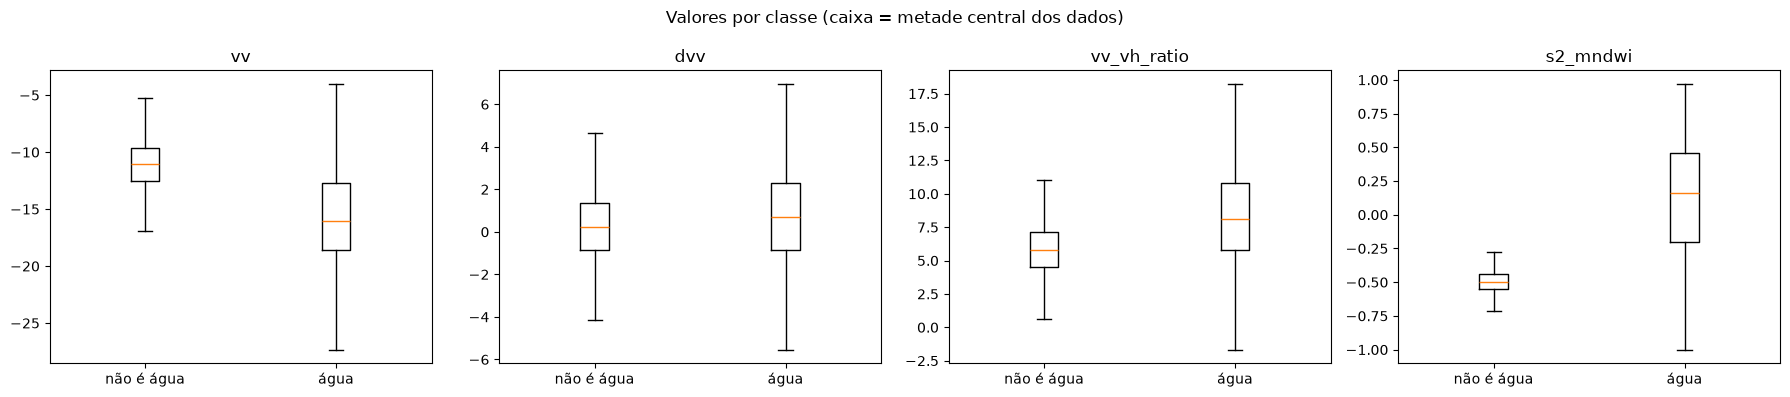

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["vv", "dvv", "vv_vh_ratio", "s2_mndwi"]):
    data = [table.loc[table["label_water"] == v, col].dropna() for v in (0, 1)]
    ax.boxplot(data, tick_labels=["não é água", "água"], showfliers=False); ax.set_title(col)
plt.suptitle("Valores por classe (caixa = metade central dos dados)"); plt.tight_layout()
plt.savefig(REPORTS / "28_features_por_classe.png", dpi=110)

from sklearn.metrics import roc_auc_score
rows = []
for col in ["vv", "vh", "vv_p10", "vh_p10", "dvv", "dvv_p10", "dvh_p10", "vv_vh_ratio", "s2_mndwi", "s2_ndwi", "dw_water", "hand"]:
    ok = table[col].notna()
    auc = roc_auc_score(table.loc[ok, "label_water"], table.loc[ok, col], sample_weight=table.loc[ok, "weight"])
    rows.append({"feature": col, "linhas": int(ok.sum()), "AUC": max(auc, 1 - auc), "água tem valores": "mais altos" if auc > 0.5 else "mais baixos"})
pd.DataFrame(rows).sort_values("AUC", ascending=False)

**Como ler a tabela.** O AUC mede quão bem cada feature, sozinha, separa água de
não-água (0,5 = não ajuda, 1 = separa perfeitamente). É um primeiro olhar, não um
modelo: serve para confirmar que os dados têm sinal antes da Semana 3.

## 5. Teste independente: a cheia de janeiro de 2026 (Copernicus EMS)

As linhas com `label_source = ems` vêm do mapa oficial da cheia de janeiro de
2026 (notebook 26) e nunca entram no treino. A tabela compara, só nessas linhas,
a mediana do mês com o momento mais escuro do mês (`_p10`).

In [6]:
ems = table[table["label_source"] == "ems"]
rows = []
for col in ["vv", "vh", "vv_p10", "vh_p10", "dvv_p10", "dvh_p10", "s2_mndwi", "dw_water", "hand"]:
    ok = ems[col].notna()
    if ok.sum() > 100:
        auc = roc_auc_score(ems.loc[ok, "label_water"], ems.loc[ok, col])
        rows.append({"feature": col, "linhas": int(ok.sum()), "AUC": max(auc, 1 - auc),
                     "mediana alagado": ems.loc[ok & (ems["label_water"] == 1), col].median(),
                     "mediana não alagado": ems.loc[ok & (ems["label_water"] == 0), col].median()})
teste = pd.DataFrame(rows).sort_values("AUC", ascending=False)
teste.round(3).to_csv(REPORTS / "28_teste_ems_janeiro_2026.csv", index=False)
teste

,feature,linhas,AUC,mediana alagado,mediana não alagado
5,dvh_p10,40000,0.974,-15.260,-1.280
3,vh_p10,40000,0.970,-32.380,-18.270
7,dw_water,40000,0.948,0.232,0.027
4,dvv_p10,40000,0.917,-6.625,-0.950
2,vv_p10,40000,0.912,-17.670,-12.080
6,s2_mndwi,40000,0.878,-0.220,-0.477
8,hand,40000,0.771,1.300,5.200
1,vh,40000,0.745,-17.780,-15.730
0,vv,40000,0.675,-11.260,-9.850


**Leitura.** A cheia durou poucos dias no fim do mês. A mediana mensal (`vv`,
`vh`) fica com a imagem de antes da cheia e quase não a vê; o percentil 10
(`vv_p10`, `vh_p10`) guarda o momento mais escuro e separa bem as duas classes.
Foi por isto que as bandas `_p10` foram acrescentadas ao Sentinel-1. O Modelo B
deve usá-las.

**Porque é que `dvv` separa mal.** A mudança em relação à época seca só é grande
onde a água é **nova**. A maior parte da água desta tabela (rio, lagoas, zonas
húmidas) também lá está na época seca, por isso quase não muda. O `dvv` é útil
para encontrar cheias, não para dizer se um píxel é água.

**Limites a ter em conta**

- O rótulo JRC diz "houve água em algum momento do mês"; as features são a
  mediana do mês. Numa cheia de poucos dias, a mediana pode não mostrar a água.
  É uma fonte de erro conhecida das composições mensais.
- `dw_water` (Dynamic World) é o resultado de outro modelo treinado com
  Sentinel-2. Pode ser usado como feature, nunca como rótulo.
- A tabela só tem linhas com rótulo, ou seja, até 2021. A validação com eventos
  de 2022–2026 depende dos polígonos em `labels.gpkg`.